In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp14: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np, tensorflow as tf, networkx as nx, matplotlib.pyplot as plt
np.random.seed(14); tf.random.set_seed(14)
tokens=np.array([[1.,0.],[0.,1.],[1.,1.],[.5,.2],[.2,.8]],dtype="float32")
model=tf.keras.Sequential([tf.keras.layers.Input((5,2)),tf.keras.layers.SimpleRNN(3,return_sequences=True),tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))])
_ = model(tokens[None,...])
rnn=model.layers[0]; dense=model.layers[1].layer
Wx,Wh,b=rnn.get_weights(); Wy,by=dense.get_weights()
states=[]; h=np.zeros(3)
for xt in tokens: h=np.tanh(xt@Wx+h@Wh+b); states.append(h.copy())
states=np.array(states); keras_states=rnn(tokens[None,...]).numpy()[0]
print("Maximum manual/Keras hidden-state difference:",float(np.max(np.abs(states-keras_states))))
G=nx.DiGraph()
for t in range(5):
 G.add_node(f"x{t+1}",pos=(t,2)); G.add_node(f"h{t+1}",pos=(t,1)); G.add_node(f"y{t+1}",pos=(t,0))
 G.add_edge(f"x{t+1}",f"h{t+1}",label="W_xh"); G.add_edge(f"h{t+1}",f"y{t+1}",label="W_hy")
 if t: G.add_edge(f"h{t}",f"h{t+1}",label="W_hh")
pos=nx.get_node_attributes(G,"pos")
plt.figure(figsize=(12,4)); nx.draw(G,pos,with_labels=True,node_size=1300,node_color="lightblue",arrows=True); nx.draw_networkx_edge_labels(G,pos,edge_labels=nx.get_edge_attributes(G,"label")); plt.title("SimpleRNN unfolded across five time steps"); plt.show()
plt.figure(figsize=(8,4)); plt.plot(range(1,6),states,marker="o"); plt.xlabel("Time step"); plt.ylabel("Hidden state"); plt.title("Hidden-state values"); plt.grid(); plt.show()
print("Input, recurrent and output weight shapes:",Wx.shape,Wh.shape,Wy.shape)

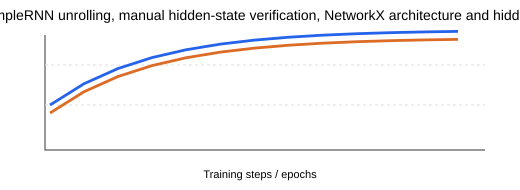

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.